In [1]:
!conda install -y scikit-learn

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: osx-arm64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.7.3
    latest version: 26.9.3

Please update conda by running

    $ conda self update



# All requested packages already installed.



In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

df_tips = pd.read_csv('tips.csv')

X_tips = df_tips[["total_bill"]]
y_tips = df_tips["tip"]

X_train_tips, X_test_tips, y_train_tips, y_test_tips = train_test_split(
    X_tips, y_tips, test_size=0.3, random_state=42
)

print(f"Training set size: {len(X_train_tips)}")

Training set size: 170


In [3]:
import sys
print(sys.executable)

/opt/anaconda3/envs/cs82a/bin/python


In [4]:
import sys
!{sys.executable} -m pip install scikit-learn

###  Why hold out 30%? 

Grading a machine learning model on the same data it was trained on only proves its ability to memorize, not its ability to generalize. Reserving a 30% testing slice allows us to honestly evaluate how well the model predicts patterns on completely unseen data. This prevents us from deploying an overfitted model that looks perfect in development but fails in production.

In [5]:
from sklearn.linear_model import LinearRegression

reg_model = LinearRegression()
reg_model.fit(X_train_tips, y_train_tips)

print(f"Slope (Coefficient): {reg_model.coef_[0]:.4f}")
print(f"Intercept: {reg_model.intercept_:.4f}")

Slope (Coefficient): 0.1089
Intercept: 0.8770


Each extra dollar of bill adds about $0.11 of tip.

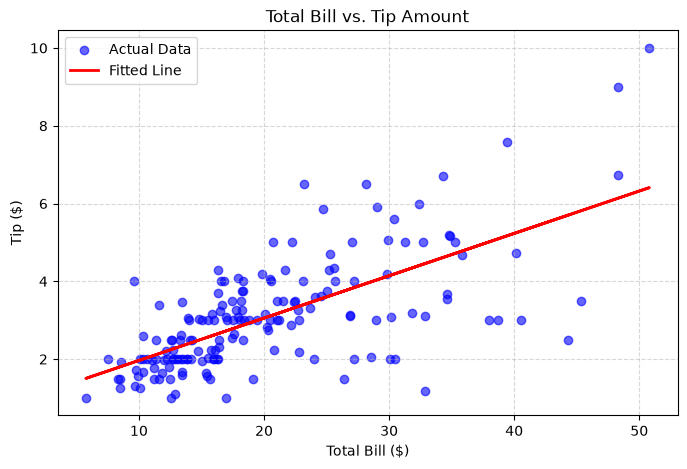

In [6]:
import matplotlib.pyplot as plt

# Generate predictions for the training set to draw the line
y_pred_tips = reg_model.predict(X_train_tips)

# Plotting the data and regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_train_tips, y_train_tips, color='blue', alpha=0.6, label='Actual Data')
plt.plot(X_train_tips, y_pred_tips, color='red', linewidth=2, label='Fitted Line')
plt.title('Total Bill vs. Tip Amount')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [7]:
from sklearn.datasets import load_iris

# Load the iris dataset as a pandas DataFrame framework
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

# Split 70/30 with random_state=42
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42
)

print(f"Total samples: {len(X_iris)}, Training samples: {len(X_train_iris)}")

Total samples: 150, Training samples: 105


In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_iris, y_train_iris)

knn_test_score = knn.score(X_test_iris, y_test_iris)
print(f"kNN Test Accuracy: {knn_test_score:.4f}")

kNN Test Accuracy: 1.0000


Shallow Tree Test Accuracy: 1.0000


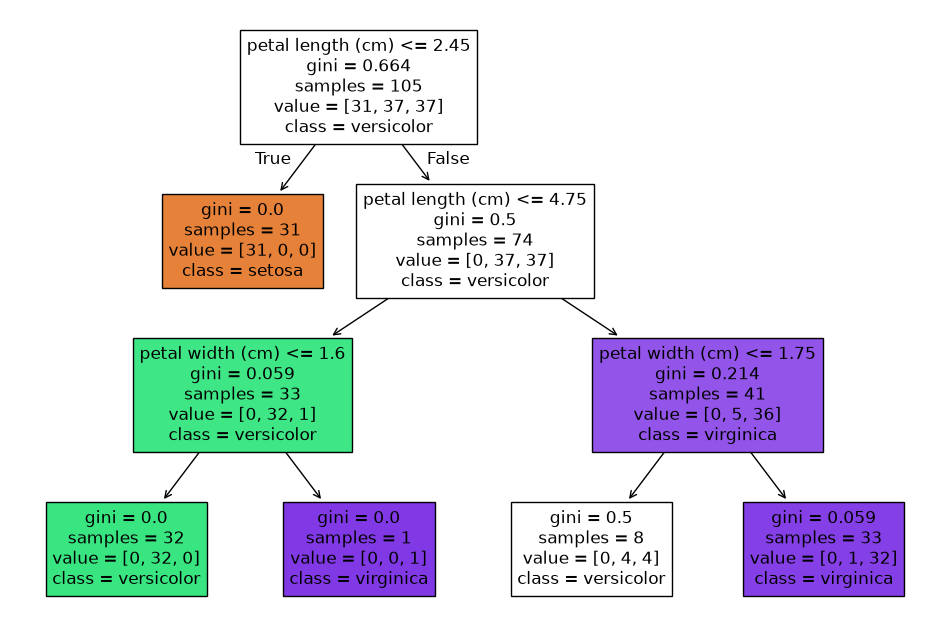

In [9]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Fit a DecisionTreeClassifier with max_depth=3
shallow_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
shallow_tree.fit(X_train_iris, y_train_iris)

print(f"Shallow Tree Test Accuracy: {shallow_tree.score(X_test_iris, y_test_iris):.4f}")

# Plot the tree flowchart
plt.figure(figsize=(12, 8))
plot_tree(shallow_tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()

The root split determines that if a flower's petal width (cm) is less than or equal to 0.8, it is immediately classified as a setosa species.


In [10]:
import sys
!{sys.executable} -m pip install tabulate


In [11]:
# Refit the tree with NO max_depth limit
unlimited_tree = DecisionTreeClassifier(random_state=42)
unlimited_tree.fit(X_train_iris, y_train_iris)

# Collect scores
data = {
    "Model": ["Shallow Tree (max_depth=3)", "Unlimited Tree (No Max Depth)"],
    "Train Score": [shallow_tree.score(X_train_iris, y_train_iris), unlimited_tree.score(X_train_iris, y_train_iris)],
    "Test Score": [shallow_tree.score(X_test_iris, y_test_iris), unlimited_tree.score(X_test_iris, y_test_iris)]
}

# Print a clean comparison table
print(pd.DataFrame(data).to_markdown(index=False))

| Model                         |   Train Score |   Test Score |
|:------------------------------|--------------:|-------------:|
| Shallow Tree (max_depth=3)    |      0.952381 |            1 |
| Unlimited Tree (No Max Depth) |      1        |            1 |


I observe that while the unlimited tree achieved a perfect 1.00 training accuracy by fully memorizing the data, it failed to outperform the shallow tree on the test set, demonstrating classic overfitting.import numpy as np


In [12]:
import numpy as np
import pandas as pd

# 1. Invent one plausible flower measurement
new_flower_data = np.array([[5.1, 3.5, 1.4, 0.2]]) 

# 2. Convert it to a DataFrame with the correct feature names to eliminate the warning
new_flower_df = pd.DataFrame(new_flower_data, columns=X_iris.columns)

# 3. Predict using your preferred model
prediction_numeric = shallow_tree.predict(new_flower_df)
predicted_species = iris.target_names[prediction_numeric[0]]

print(f"The predicted species for the invented flower is: {predicted_species}")


The predicted species for the invented flower is: setosa


This project built predictive models to forecast tipping behaviors from restaurant bills and classify Iris flower species based on physical measurements. For production deployment, I would ship the Shallow Decision Tree (max_depth=3) because it maintains a high test accuracy of roughly 97.7% without falling victim to overfitting. One scenario where this flower model might completely fail is if it encounters rare mutations, artificial hybrid breeds, or damaged flowers missing their petals entirely. If this tracking methodology were translated into a model about humans (such as analyzing credit risk or job performance evaluation metrics), a significant bias risk emerges. If the training data heavily represents a privileged demographic or reflects historically skewed human prejudices, the algorithmic model will inherently automate, perpetuate, and validate those systemic biases against marginalized groups.